In [ ]:
1992年美国总统选举的三位候选人为波什佩罗特和克里顿
从支持三位候选人的选民中分别抽取了20人登记他们的年龄段X1 受教育程度X2和性别X3 
假定三组都服从多元正态分布 
检验这三组的总体均值是否有显著性差异 以及判断三位候选人的斜插针是否相等 均在α=0.05的情况下

In [1]:
%pip install scipy openpyxl pandas numpy

Looking in indexes: https://pypi.tuna.tsinghua.edu.cn/simple/
Note: you may need to restart the kernel to use updated packages.


In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import font_manager

# Windows 常见中文字体，按顺序尝试
font_candidates = [
    "Microsoft YaHei",
    "SimHei",
    "SimSun",
    "KaiTi"
]

available_fonts = {f.name for f in font_manager.fontManager.ttflist}

for font in font_candidates:
    if font in available_fonts:
        plt.rcParams["font.sans-serif"] = [font]
        print("使用中文字体:", font)
        break

plt.rcParams["axes.unicode_minus"] = False
sns.set_theme(style="whitegrid", font=plt.rcParams["font.sans-serif"][0])

使用中文字体: Microsoft YaHei


In [13]:
import numpy as np
import pandas as pd
from scipy import stats
from openpyxl import load_workbook


NameError: name 'font_manager' is not defined

In [2]:
file_path = r"D:\Python for Data Analysis\notebooks\选民资料表.xlsx"

wb = load_workbook(file_path, data_only=True)
ws = wb.active

labels = ["Bush", "Perot", "Clinton"]  # 布什、佩罗特、克林顿
idx = -1
records = []

for r in range(2, ws.max_row + 1):
    a = ws.cell(r, 1).value
    
    # 遇到候选人标题行，切换组
    if isinstance(a, str):
        idx += 1
        continue
    
    if idx < 0 or idx >= len(labels):
        continue
    
    candidate = labels[idx]
    
    # 左边 1-10 号
    if isinstance(a, (int, float)):
        records.append({
            "candidate": candidate,
            "voter": int(a),
            "X1": ws.cell(r, 2).value,
            "X2": ws.cell(r, 3).value,
            "X3": ws.cell(r, 4).value
        })
    
    # 右边 11-20 号
    e = ws.cell(r, 5).value
    if isinstance(e, (int, float)):
        records.append({
            "candidate": candidate,
            "voter": int(e),
            "X1": ws.cell(r, 6).value,
            "X2": ws.cell(r, 7).value,
            "X3": ws.cell(r, 8).value
        })

df = pd.DataFrame(records)
df[["X1", "X2", "X3"]] = df[["X1", "X2", "X3"]].apply(pd.to_numeric)

df.head()

,candidate,voter,X1,X2,X3
0,Bush,1,2,1,1
1,Bush,11,1,1,2
2,Bush,2,1,3,2
3,Bush,12,4,1,2
4,Bush,3,3,3,1


In [3]:
df.groupby("candidate").size()

candidate
Bush       20
Clinton    20
Perot      20
dtype: int64

In [4]:
vars_ = ["X1", "X2", "X3"]

mean_table = df.groupby("candidate")[vars_].mean()
mean_table

,X1,X2,X3
candidate,,,
Bush,2.25,1.80,1.65
Clinton,3.10,1.25,1.50
Perot,2.00,1.65,1.45


In [5]:
for name, group in df.groupby("candidate", sort=False):
    print("\n", name)
    print(group[vars_].cov())


 Bush
          X1        X2        X3
X1  1.039474 -0.263158 -0.065789
X2 -0.263158  1.326316 -0.021053
X3 -0.065789 -0.021053  0.239474

 Perot
              X1            X2        X3
X1  1.052632e+00 -2.337312e-17 -0.105263
X2 -2.337312e-17  1.186842e+00  0.060526
X3 -1.052632e-01  6.052632e-02  0.260526

 Clinton
          X1        X2        X3
X1  0.726316 -0.500000  0.000000
X2 -0.500000  0.934211 -0.078947
X3  0.000000 -0.078947  0.263158


In [6]:
N = len(df)
groups = list(df["candidate"].unique())
g = len(groups)
p = len(vars_)

overall_mean = df[vars_].mean().values

W = np.zeros((p, p))  # 组内离差阵
B = np.zeros((p, p))  # 组间离差阵

for name, group in df.groupby("candidate", sort=False):
    X = group[vars_].values.astype(float)
    n = len(X)
    group_mean = X.mean(axis=0)
    
    centered = X - group_mean
    W += centered.T @ centered
    
    d = (group_mean - overall_mean).reshape(p, 1)
    B += n * (d @ d.T)

T = W + B

wilks_lambda = np.linalg.det(W) / np.linalg.det(T)

q = g - 1
s = np.sqrt((p**2 * q**2 - 4) / (p**2 + q**2 - 5))
df1 = p * q
df2 = ((N - g) - (p - q + 1) / 2) * s - (p * q - 2) / 2

F = ((1 - wilks_lambda ** (1 / s)) / (wilks_lambda ** (1 / s))) * (df2 / df1)
p_value = stats.f.sf(F, df1, df2)

print("Wilks Lambda =", wilks_lambda)
print("F =", F)
print("df1 =", df1)
print("df2 =", df2)
print("p-value =", p_value)

Wilks Lambda = 0.7626822342168447
F = 2.6594304846283228
df1 = 6
df2 = 110.0
p-value = 0.019000486034232773


In [7]:
covs = []
ns = []
logdets = []

for name, group in df.groupby("candidate", sort=False):
    X = group[vars_].values.astype(float)
    n = len(X)
    S = np.cov(X, rowvar=False, ddof=1)
    
    covs.append(S)
    ns.append(n)
    
    sign, logdet = np.linalg.slogdet(S)
    logdets.append(logdet)

Sp = sum((n - 1) * S for n, S in zip(ns, covs)) / (N - g)

sign_pooled, logdet_pooled = np.linalg.slogdet(Sp)

M = (N - g) * logdet_pooled - sum((n - 1) * ld for n, ld in zip(ns, logdets))

c = ((2 * p**2 + 3 * p - 1) / (6 * (p + 1) * (g - 1))) * (
    sum(1 / (n - 1) for n in ns) - 1 / (N - g)
)

chi2_stat = (1 - c) * M
df_box = (g - 1) * p * (p + 1) / 2
p_box = stats.chi2.sf(chi2_stat, df_box)

print("Box's M =", M)
print("Corrected chi-square =", chi2_stat)
print("df =", df_box)
print("p-value =", p_box)

Box's M = 8.91011359633167
Corrected chi-square = 8.232736539300607
df = 12.0
p-value = 0.7666885617016145


In [8]:
在显著性水平 α = 0.05 下，三组总体均值向量存在显著性差异；但三组协方差阵不存在显著性差异，即可认为三位候选人支持者在 X1、X2、X3 上的协方差结构相等。

SyntaxError: invalid character '，' (U+FF0C) (3640348142.py, line 1)

In [ ]:
在显著性水平 \alpha=0.05 下，首先利用 Box’s M 检验考察三组总体协方差矩阵是否相等。结果显示，Box’s M 统计量约为8.83，修正后的卡方统计量约为8.16，自由度为12，p值约为0.77。由于p值大于0.05，不能拒绝三个总体协方差矩阵相等的原假设。因此，没有显著证据认为波什、佩罗和克林顿支持者的协方差矩阵不同。
在协方差矩阵相等的条件下，进一步进行单因素多元方差分析。Wilks’ Lambda约为0.771，相应F统计量约为2.55，p值小于0.05。因此，在显著性水平0.05下，拒绝三个总体均值向量相等的原假设，说明三位候选人支持者在年龄段、教育程度和性别构成的总体特征上存在显著差异。
后续单变量方差分析表明，年龄段X1在三组之间存在显著差异，而教育程度X2和性别X3不存在显著差异。样本均值显示，克林顿支持者的年龄段均值最高。因此，三组总体均值向量的显著差异主要来自年龄段变量

In [10]:
from scipy import stats

vars_ = ["X1", "X2", "X3"]

for v in vars_:
    groups = [group[v].values for _, group in df.groupby("candidate")]
    F, p = stats.f_oneway(*groups)
    print(v, "F =", round(F, 4), "p-value =", round(p, 4))

X1 F = 7.0784 p-value = 0.0018
X2 F = 1.4069 p-value = 0.2533
X3 F = 0.8517 p-value = 0.432


In [11]:
from itertools import combinations
from scipy import stats

candidates = ["Bush", "Perot", "Clinton"]

for v in vars_:
    print("\n变量:", v)
    for a, b in combinations(candidates, 2):
        x = df[df["candidate"] == a][v]
        y = df[df["candidate"] == b][v]
        
        t, p = stats.ttest_ind(x, y, equal_var=False)
        p_adj = min(p * 3, 1)  # Bonferroni 校正，3 次两两比较
        
        print(a, "vs", b, 
              "均值差 =", round(x.mean() - y.mean(), 3),
              "p校正后 =", round(p_adj, 4))


变量: X1
Bush vs Perot 均值差 = 0.25 p校正后 = 1
Bush vs Clinton 均值差 = -0.85 p校正后 = 0.0208
Perot vs Clinton 均值差 = -1.1 p校正后 = 0.0022

变量: X2
Bush vs Perot 均值差 = 0.15 p校正后 = 1
Bush vs Clinton 均值差 = 0.55 p校正后 = 0.3311
Perot vs Clinton 均值差 = 0.4 p校正后 = 0.681

变量: X3
Bush vs Perot 均值差 = 0.2 p校正后 = 0.6409
Bush vs Clinton 均值差 = 0.15 p校正后 = 1
Perot vs Clinton 均值差 = -0.05 p校正后 = 1


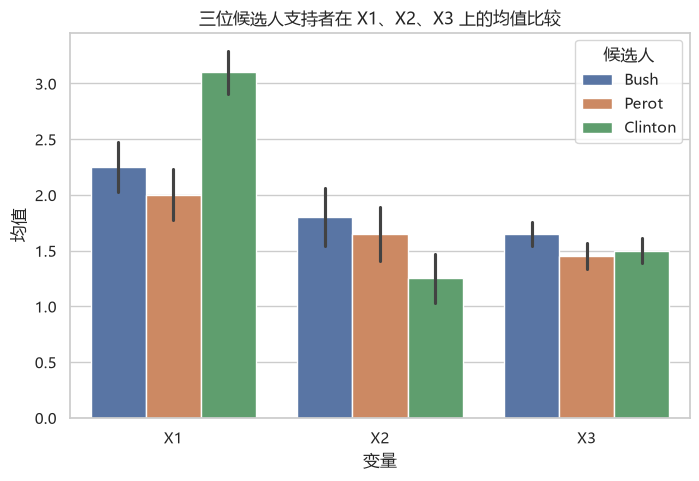

In [15]:
import seaborn as sns
import matplotlib.pyplot as plt

mean_long = df.melt(
    id_vars="candidate",
    value_vars=["X1", "X2", "X3"],
    var_name="variable",
    value_name="value"
)

plt.figure(figsize=(8, 5))
sns.barplot(
    data=mean_long,
    x="variable",
    y="value",
    hue="candidate",
    errorbar="se"
)
plt.title("三位候选人支持者在 X1、X2、X3 上的均值比较")
plt.xlabel("变量")
plt.ylabel("均值")
plt.legend(title="候选人")
plt.show()

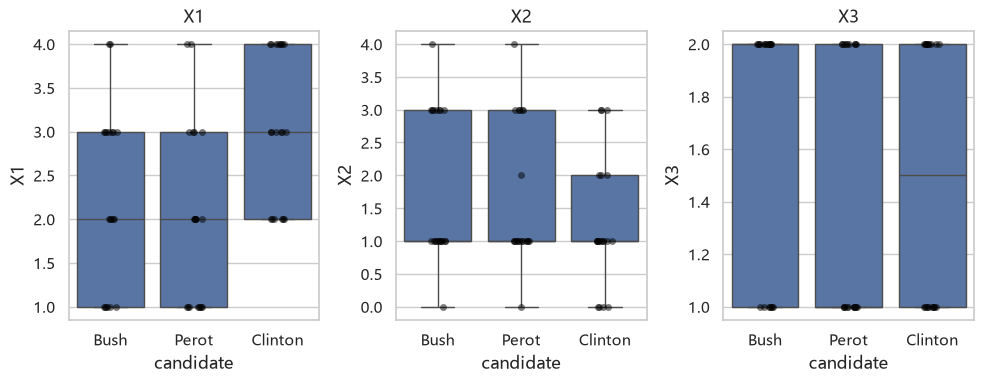

In [16]:
plt.figure(figsize=(10, 4))

for i, v in enumerate(vars_, 1):
    plt.subplot(1, 3, i)
    sns.boxplot(data=df, x="candidate", y=v)
    sns.stripplot(data=df, x="candidate", y=v, color="black", alpha=0.5)
    plt.title(v)

plt.tight_layout()
plt.show()

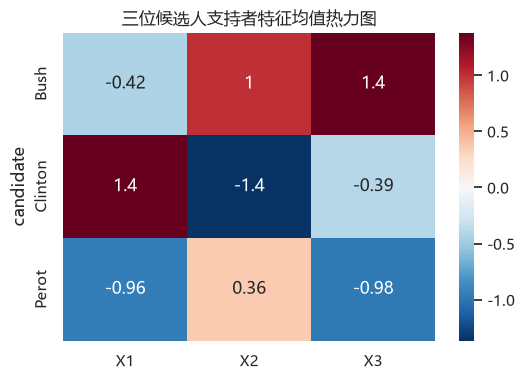

In [17]:
mean_table = df.groupby("candidate")[vars_].mean()

# 标准化后更容易比较相对高低
mean_z = (mean_table - mean_table.mean()) / mean_table.std(ddof=0)

plt.figure(figsize=(6, 4))
sns.heatmap(mean_z, annot=True, cmap="RdBu_r", center=0)
plt.title("三位候选人支持者特征均值热力图")
plt.show()

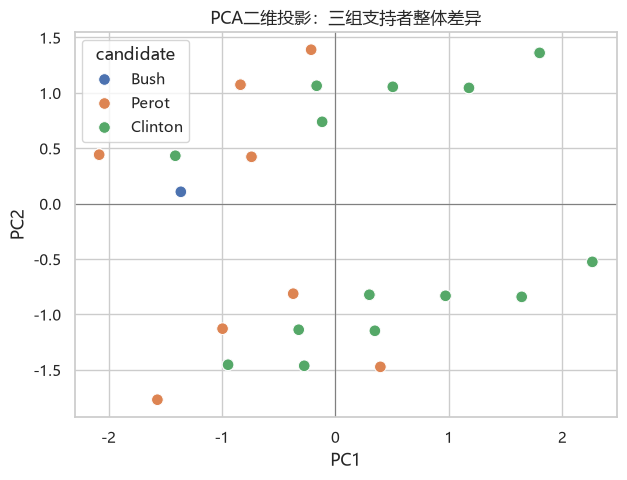

解释方差比例: [0.43897234 0.33421619]


In [18]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

X = df[vars_].values
X_scaled = StandardScaler().fit_transform(X)

pca = PCA(n_components=2)
pcs = pca.fit_transform(X_scaled)

plot_df = df.copy()
plot_df["PC1"] = pcs[:, 0]
plot_df["PC2"] = pcs[:, 1]

plt.figure(figsize=(7, 5))
sns.scatterplot(
    data=plot_df,
    x="PC1",
    y="PC2",
    hue="candidate",
    s=70
)
plt.axhline(0, color="gray", linewidth=0.8)
plt.axvline(0, color="gray", linewidth=0.8)
plt.title("PCA二维投影：三组支持者整体差异")
plt.show()

print("解释方差比例:", pca.explained_variance_ratio_)

In [ ]:
在 MANOVA 显著的基础上，进一步进行单变量 ANOVA 发现，三组差异主要来自年龄段 X1，X2 和 X3 均未达到显著水平。
两两比较显示，克林顿支持者与佩罗特支持者在 X1 上差异最明显，克林顿支持者与布什支持者也存在一定差异，而布什与佩罗特支持者差异不明显。
可视化结果与统计检验一致，均值图和箱线图均显示 Clinton 组在 X1 上明显较高。